# Ising model introduction

Fixed minus boundary, $h=\lambda/N$, and $H=-\sum_{\langle x,y\rangle}\sigma_x\sigma_y-h\sum_x\sigma_x$. The state includes the fixed frame.

Run cells in order. Install the package with the notebook extra first (see README).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from ising import IsingModel, Simulator
from ising.experiments.trajectory import run

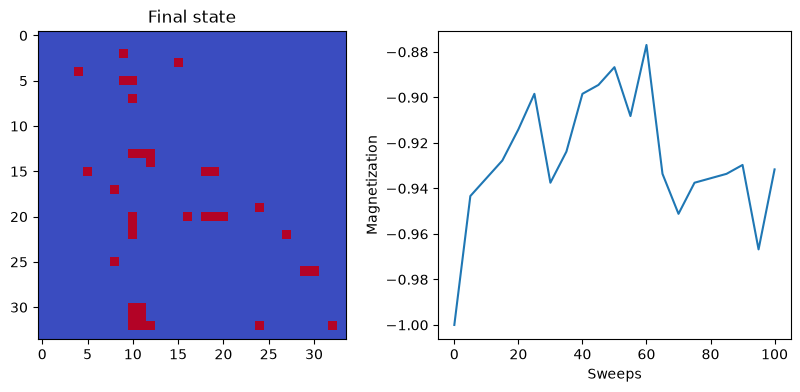

In [2]:
N,beta,lam,seed=32,.55,3.,42
state,rows=run(IsingModel(N,beta,lam),100,seed=seed,record_every=5,observables={'clusters':True})
fig,ax=plt.subplots(1,2,figsize=(10,4))
ax[0].imshow(state,cmap='coolwarm',vmin=-1,vmax=1); ax[0].set_title('Final state')
ax[1].plot([r['sweep'] for r in rows],[r['magnetization'] for r in rows]); ax[1].set(xlabel='Sweeps',ylabel='Magnetization'); plt.show()

In [ ]:
import importlib.util
if importlib.util.find_spec("ipywidgets") is None:
    print("Install the notebook extra to enable interactive controls.")
else:
    # Optional interactive controls; click Run simulation after changing parameters.
    import ipywidgets as w
    from IPython.display import display, clear_output
    size=w.IntSlider(value=32,min=8,max=128,step=8,description='N')
    beta=w.FloatSlider(value=.55,min=.2,max=1,step=.05,description='beta')
    lam=w.FloatSlider(value=3,min=0,max=10,step=.25,description='lambda')
    k=w.Dropdown(options=['heatbath','metropolis','sw-ghost','sw-size'],description='Dynamics')
    i=w.Dropdown(options=['minus','plus','random'],description='Initial')
    s=w.IntSlider(value=100,min=10,max=500,step=10,description='Steps')
    button=w.Button(description='Run simulation'); out=w.Output()
    def execute(_):
        with out:
            clear_output(wait=True)
            state,rows=run(IsingModel(size.value,beta.value,lam.value),s.value,init=i.value,dynamics=k.value,seed=42,record_every=5,observables={'clusters':True})
            fig,ax=plt.subplots(1,2,figsize=(10,4))
            ax[0].imshow(state,cmap='coolwarm',vmin=-1,vmax=1)
            for key in ['magnetization','largest_plus_fraction']:
                ax[1].plot([r['sweep'] for r in rows],[r[key] for r in rows],label=key)
            ax[1].legend(); ax[1].set_xlabel('Sweeps or cluster steps'); plt.show(); plt.close(fig)
    button.on_click(execute)
    display(w.VBox([size,beta,lam,k,i,s,button,out]))